# Actividad B

Se analiza una imagen termográfica de un sistema fotovoltáico del dataset `Photovoltaic system thermography`. La copia de trabajo es `Datos/Imagen_2D/PV_Termografia/trabajo/termografia_panel_001R.jpg`.

La imagen se inspecciona como RGB. Sus canales son valores de color codificados en el archivo y no temperaturas calibradas; por eso el histograma se interpreta como distribucion de intensidades RGB, no como una medicion termica directa.

In [1]:
from pathlib import Path
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

ruta = Path("../Datos/Imagen_2D/PV_Termografia/trabajo/termografia_panel_001R.jpg")

with Image.open(ruta) as imagen_abierta:
    formato = imagen_abierta.format
    modo = imagen_abierta.mode
    imagen = imagen_abierta.copy()

pixeles = np.asarray(imagen)
print("Formato:", formato)
print("Modo:", modo)
print("Forma del arreglo:", pixeles.shape)
print("Ancho x alto:", imagen.width, "x", imagen.height)
print("Canales:", pixeles.shape[2] if pixeles.ndim == 3 else 1)
print("Bytes aproximados del arreglo:", pixeles.nbytes)
print("Rango global:", int(pixeles.min()), "a", int(pixeles.max()))


Formato: JPEG
Modo: RGB
Forma del arreglo: (512, 640, 3)
Ancho x alto: 640 x 512
Canales: 3
Bytes aproximados del arreglo: 983040
Rango global: 15 a 237


## Imagen original e histograma por canal

La imagen se muestra sin convertirla a escala de grises para conservar la informacion RGB. El histograma se etiqueta por canal y resume los valores codificados en cada componente.

C:\Users\Gotoh\AppData\Local\Temp\ipykernel_44008\2293490230.py:19: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


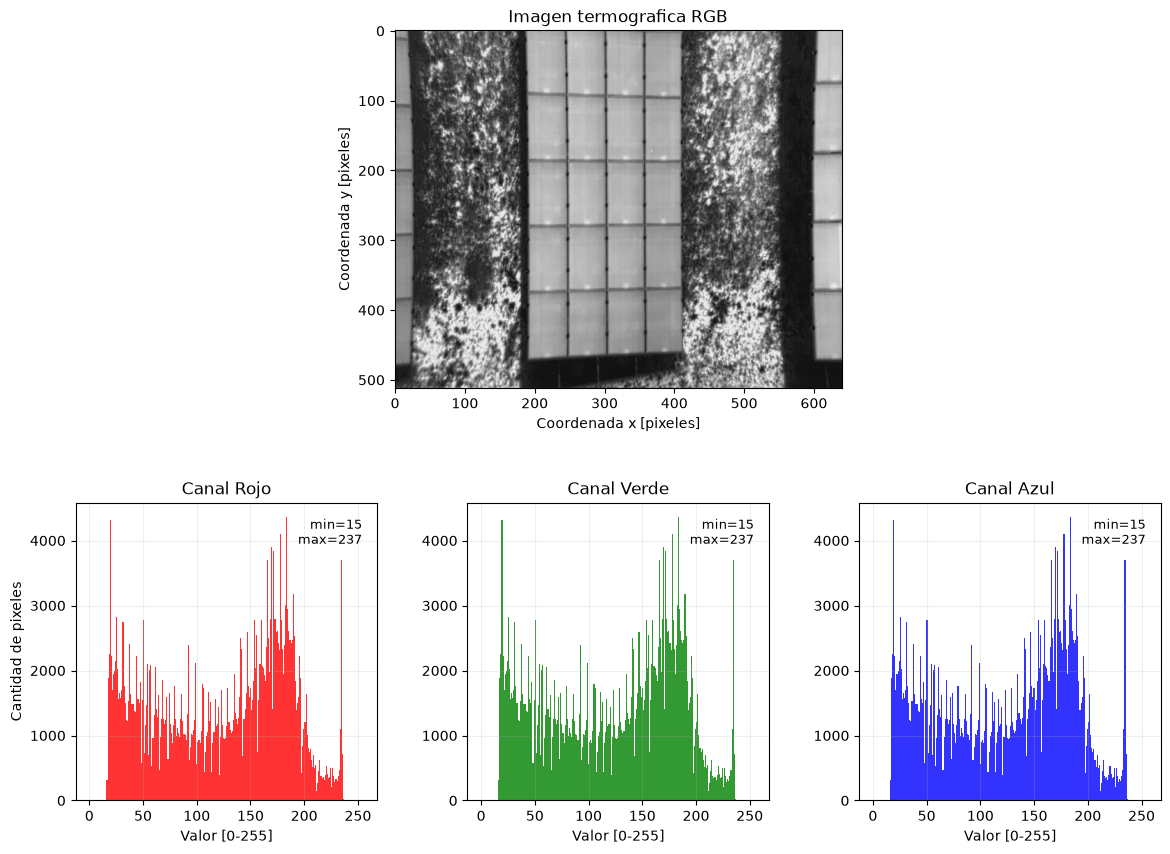

In [2]:
fig = plt.figure(figsize=(14, 10))
disposicion = fig.add_gridspec(2, 3, height_ratios=[1.2, 1], hspace=0.35, wspace=0.3)
eje_imagen = fig.add_subplot(disposicion[0, :])
ejes = [fig.add_subplot(disposicion[1, canal]) for canal in range(3)]
eje_imagen.imshow(imagen)
eje_imagen.set_title("Imagen termografica RGB")
eje_imagen.set_xlabel("Coordenada x [pixeles]")
eje_imagen.set_ylabel("Coordenada y [pixeles]")

colores = ["red", "green", "blue"]
nombres = ["Rojo", "Verde", "Azul"]
for canal, color, nombre, eje in zip(range(3), colores, nombres, ejes):
    eje.hist(pixeles[:, :, canal].ravel(), bins=256, range=(0, 255), color=color, alpha=0.8)
    eje.set_title(f"Canal {nombre}")
    eje.set_xlabel("Valor [0-255]")
    eje.grid(True, alpha=0.2)
    eje.text(0.95, 0.95, f"min={pixeles[:, :, canal].min()}\nmax={pixeles[:, :, canal].max()}", transform=eje.transAxes, ha="right", va="top", fontsize=9)
ejes[0].set_ylabel("Cantidad de pixeles")
fig.tight_layout()
plt.show()


## Inspección de calidad

Se comprueba que el arreglo RGB tenga la forma esperada y que sus valores estén dentro del rango de un JPEG de 8 bits. No se buscan NaN o Inf como si fueran intensidades físicas: este arreglo es entero, por lo que esa comprobación no es pertinente del mismo modo que en datos flotantes.

In [3]:
valores_fuera_de_rango = int(((pixeles < 0) | (pixeles > 255)).sum())
saturados_bajo = int((pixeles == 0).sum())
saturados_alto = int((pixeles == 255).sum())
canales_constantes = [int(np.ptp(pixeles[:, :, canal])) == 0 for canal in range(3)]

print("Forma RGB esperada (alto, ancho, canales):", pixeles.shape == (imagen.height, imagen.width, 3))
print("Valores fuera de 0-255:", valores_fuera_de_rango)
print("Pixeles/canales en 0:", saturados_bajo)
print("Pixeles/canales en 255:", saturados_alto)
print("Canales constantes:", canales_constantes)


Forma RGB esperada (alto, ancho, canales): True
Valores fuera de 0-255: 0
Pixeles/canales en 0: 0
Pixeles/canales en 255: 0
Canales constantes: [False, False, False]


## Interpretación y limitaciones

Convertir RGB a gris reemplazaría tres componentes por una sola intensidad ponderada y perdería diferencias de color. Interpretar directamente una imagen multicanal como una matriz escalar tambien ocultaría la información de los otros canales. El histograma no demuestra por si solo la presencia de una falla, una temperatura específica, un material o una condición operacional. Para diagnosticar un panel se necesitarían calibración radiométrica, emisividad, condiciones ambientales, distancia de captura, identificación del equipo y validación experta.